<h1>EN 3160 - Assignment 2</h1>
<h2>Fitting and Alignment</h2>
<h3>Index No. - 230013A</h3>
<h3>Name - D. H. Abeywarna</h3>
Github - <a href="https://github.com/dilith813/en3160-a02">https://github.com/dilith813/en3160-a02</a>

# Question 1: Blob detection with the Laplacian of Gaussian

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Loading the image
im = cv.imread('../images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "image not found: check the path in images/"
rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)

# Single channel versions to detect blobs on
b, g, r = [c.astype(np.float32) / 255 for c in cv.split(im)]
gray_ch = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255
yellow_ch = np.clip((r + g) / 2 - b, 0, None)     # high on yellow petals, zero on sky and clouds
print(im.shape)

(360, 360, 3)


In [2]:
# Scale-space blob detector using scale-normalized Laplacian of Gaussian
def detect_blobs(img, sigmas, thr_rel=0.3, color_mask=None, min_color=0.15):
    space = np.empty((len(sigmas),) + img.shape, np.float32)
    for i, s in enumerate(sigmas):
        blurred = cv.GaussianBlur(img, (0, 0), s)
        space[i] = -(s ** 2) * cv.Laplacian(blurred, cv.CV_32F)

    # Scale-space extrema
    is_max = space == maximum_filter(space, size=(3, 3, 3))
    pts = np.argwhere(is_max & (space > thr_rel * space.max()))
    cands = sorted([(space[l, y, x], x, y, sigmas[l]) for l, y, x in pts], reverse=True)

    keep = []
    for resp, x, y, s in cands:
        if color_mask is not None and color_mask[y, x] <= min_color:
            continue
        if all(np.hypot(x - xk, y - yk) > max(np.sqrt(2) * s, np.sqrt(2) * sk) for _, xk, yk, sk in keep):
            keep.append((resp, x, y, s))
    return keep

In [8]:
# Draw circles (radius = sqrt(2) * sigma)
def show(circles, title, n=5):
    out = rgb.copy()
    for _, x, y, s in circles:
        cv.circle(out, (int(x), int(y)), int(round(np.sqrt(2) * s)), (255, 0, 0), 2)
    plt.figure(figsize=(9, 7)); plt.imshow(out)
    plt.xticks(range(0, out.shape[1], 50)); plt.yticks(range(0, out.shape[0], 50))
    plt.grid(alpha=0.3); plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)')
    plt.title(f"{title}: {len(circles)} circles"); plt.show()
    print(f"{'x':>5} {'y':>5} {'sigma':>7} {'radius':>7}")
    for _, x, y, s in sorted(circles, key=lambda c: c[3], reverse=True)[:n]:
        print(f"{x:5d} {y:5d} {s:7.2f} {np.sqrt(2) * s:7.1f}")

**Method:** A blob is a region that stands out from its surroundings at some size.The Laplacian of Gaussian (LoG) responds strongly where the image, smoothed with a Gaussian of width sigma ($\sigma$) has a bright spot of about that size. To find blobs of every size, the image is processed at a range of $\sigma$ values (the scale space). The response is multiplied by sigma squared, otherwise larger sigmas would always give weaker responses and big blobs would never win. A blob is detected where the response is a maximum in position and in scale, and above a threshold. Here, maximum means it has to be larger than all 26 neighbors in the 3x3x3 neighborhood. For a circular blob of radius r, the response peaks at $\sigma$ = r / sqrt(2), so each detection is drawn as a circle of radius sqrt(2) times $\sigma$. Circles whose center lies inside a stronger circle are removed, so each flower gets only circle.

**Sigma Range:** Sigma values follow a geometric series, (3x1.2)^k. Since a blob of any size should be equally easy to detect, scales are spaced by a constant ratio. The smallest $\sigma$, 3, corresponds to a radius of 4.2 pixels. The largest $\sigma$ sets the largest detectable blob and is limited by the flower size. The first run (grayscale) used 18 levels, sigma 3 to 66.6. The final run used
14 levels, sigma 3 to 32.1 (radius 4.2 to 45.4 pixels). The ratio 1.2 and the number of levels were
chosen by judgement and not tuned.
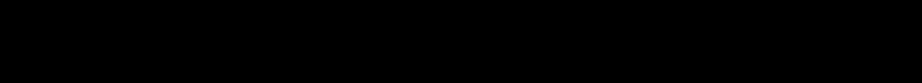
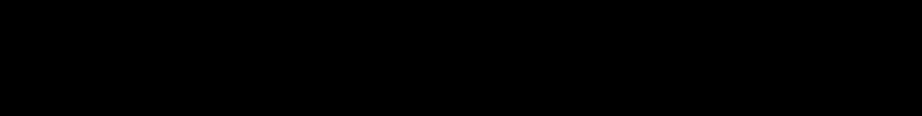
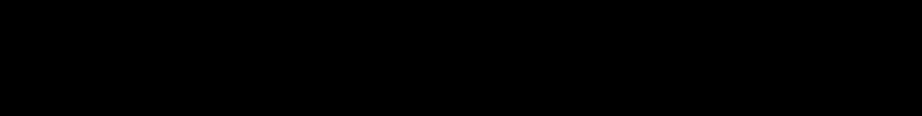
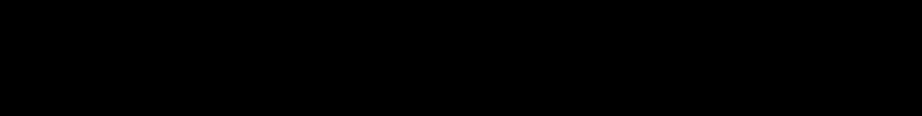
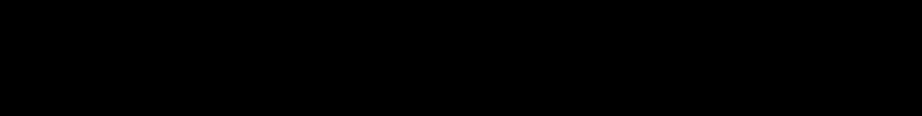

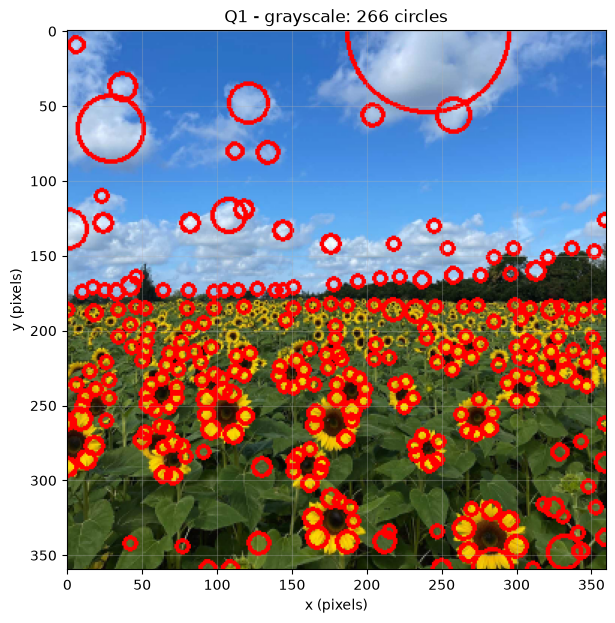

    x     y   sigma  radius
  241     0   38.52    54.5
   29    65   15.48    21.9
  284   359    8.96    12.7
  121    48    8.96    12.7
    0   132    8.96    12.7
sigma range: 3.00 to 66.56


In [9]:
# Q1 - run 1: grayscale
sig_gray = 3.0 * 1.2 ** np.arange(18)
circ_gray = detect_blobs(gray_ch, sig_gray)
show(circ_gray, "Q1 - grayscale")
print(f"sigma range: {sig_gray[0]:.2f} to {sig_gray[-1]:.2f}")

**First Attempt (Grayscale):** Four of the five largest circles were on clouds in the sky. The largest had sigma
38.52 and radius 54.5 at (241, 0), a cloud cut by the top border. Brightness alone cannot separate white clouds from yellow petals, because both are bright blobs.

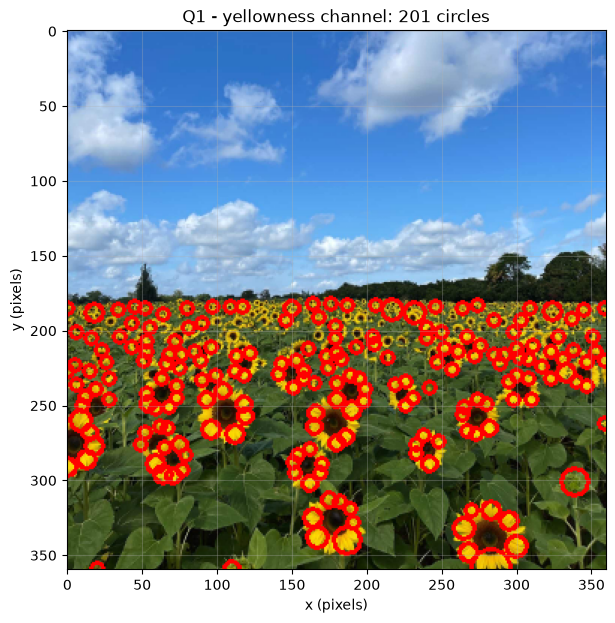

    x     y   sigma  radius
  283   359    8.96    12.7
  187   340    6.22     8.8
  339   301    6.22     8.8
  167   338    5.18     7.3
  300   344    5.18     7.3
sigma range: 3.00 to 66.56  (radius 4.2 to 94.1 px)


In [10]:
# Q1 - run 2: yellowness channel
sig = 3.0 * 1.2 ** np.arange(18)
yellow_smooth = cv.GaussianBlur(yellow_ch, (0, 0), 2)
circ_yel = detect_blobs(yellow_ch, sig, thr_rel=0.3, color_mask=yellow_smooth, min_color=0.15)
show(circ_yel, "Q1 - yellowness channel")
print(f"sigma range: {sig[0]:.2f} to {sig[-1]:.2f}  (radius {np.sqrt(2)*sig[0]:.1f} to {np.sqrt(2)*sig[-1]:.1f} px)")

**Final Detector (Yellowness Channel):** Detection was run on (R + G) / 2 - B, clipped at zero. This is high for yellow petals and zero for white clouds and the sky. The result is 201 circles, all on the sunflower field.
Re-running with 18 levels (sigma up to 66.6) also gave no sky detections. The largest detected sigma
was only 8.96, far below the upper limit, so the upper limit did not matter on this channel.

**Largest Circles (Final run):**
| x | y | sigma | radius (px) |
|---|---|---|---|
| 283 | 359 | 8.96 | 12.7 |
| 187 | 340 | 6.22 | 8.8 |
| 339 | 301 | 6.22 | 8.8 |
| 167 | 338 | 5.18 | 7.3 |
| 300 | 344 | 5.18 | 7.3 |


**Discussion and Limitations:**
- The circles mostly sit on single petals or small groups of petals, not on whole flower heads. The
  largest circle has radius 12.7 px, while the largest flower heads are about 50 px across (radius
  about 25 px). In this channel a flower head is a bright ring of petals around a dark centre, which
  gives a weaker response at the scale of the whole head than a single petal does at a smaller scale.
- Some visible petals have no circle. A detection needs a local maximum above a threshold set by the
  strongest response, so paler or shaded petals fall below it, and circles inside a stronger circle
  are removed. (However, it should be mentioned that some green parts of the flowers have been marked by a circle, despite being visually less intense than yellow petals).
- Circles cut by the image border describe only part of a blob.
